In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import KFold, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"

conn = sqlite3.connect(db_path)
data = pd.read_sql_query("SELECT * FROM agri_yield_train", conn)
conn.close()

X = data.drop(columns=["yield"]).select_dtypes(include="number")
y = data["yield"]

print("Dataset shape:", data.shape)
print("Features:", X.shape)

Dataset shape: (10000, 9)
Features: (10000, 7)


In [2]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rf = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 5]
}

rf_search = GridSearchCV(
    rf, rf_params, cv=cv, scoring="r2", n_jobs=-1
)

rf_search.fit(X, y)

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best CV R2:", round(rf_search.best_score_, 4))

Best Random Forest parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
Best CV R2: -0.0083


In [3]:
gb = GradientBoostingRegressor(random_state=42)

gb_params = {
    "n_estimators": [100, 200],
    "learning_rate": [0.03, 0.1],
    "max_depth": [2, 3]
}

gb_search = GridSearchCV(
    gb, gb_params, cv=cv, scoring="r2", n_jobs=-1
)

gb_search.fit(X, y)

print("Best Gradient Boosting parameters:", gb_search.best_params_)
print("Best CV R2:", round(gb_search.best_score_, 4))

Best Gradient Boosting parameters: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100}
Best CV R2: -0.0023


In [4]:
from sklearn.base import clone

predictions = {
    "Dummy": np.zeros(len(X)),
    "Tuned Random Forest": np.zeros(len(X)),
    "Tuned Gradient Boosting": np.zeros(len(X))
}

for train_idx, val_idx in cv.split(X):

    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train = y.iloc[train_idx]

    dummy = DummyRegressor(strategy="mean")
    dummy.fit(X_train, y_train)
    predictions["Dummy"][val_idx] = dummy.predict(X_val)

    rf_model = clone(rf_search.best_estimator_)
    rf_model.fit(X_train, y_train)
    predictions["Tuned Random Forest"][val_idx] = rf_model.predict(X_val)

    gb_model = clone(gb_search.best_estimator_)
    gb_model.fit(X_train, y_train)
    predictions["Tuned Gradient Boosting"][val_idx] = gb_model.predict(X_val)

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred)
    })

comparison = pd.DataFrame(results)
print(comparison.round(4).to_string(index=False))

                  Model      MAE     RMSE      R2
                  Dummy 378.8920 436.5463 -0.0002
    Tuned Random Forest 379.6746 438.2596 -0.0080
Tuned Gradient Boosting 379.0517 436.9624 -0.0021


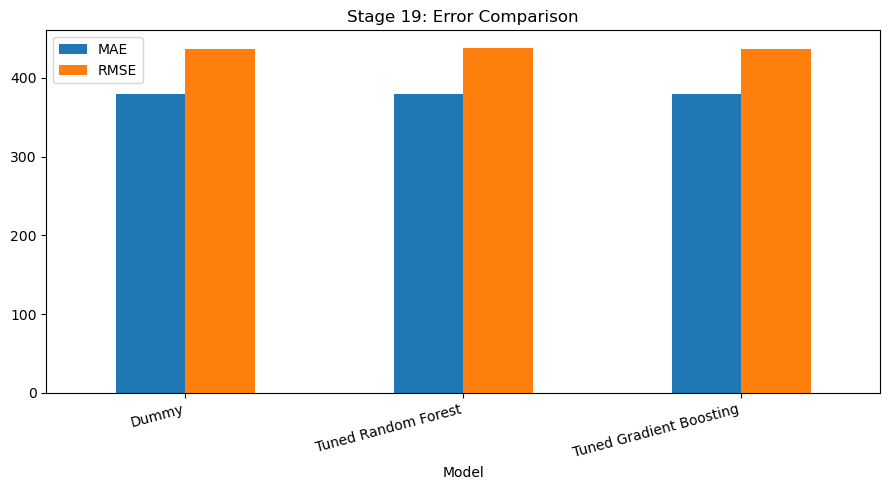

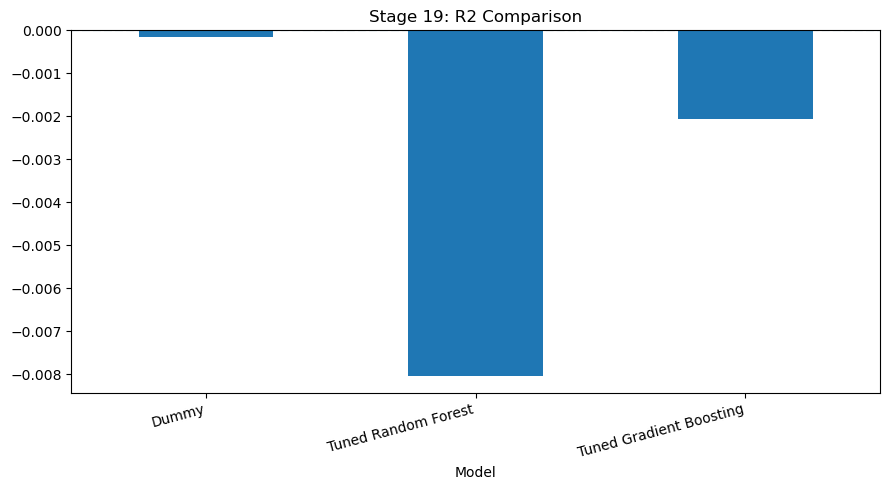

Stage 19 outputs saved successfully!


In [5]:
comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Stage 19: Error Comparison")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

comparison.set_index("Model")["R2"].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Stage 19: R2 Comparison")
plt.axhline(0, linestyle="--")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

os.makedirs("stage19_outputs", exist_ok=True)

pd.DataFrame([
    {"Model": "Random Forest",
     "Best Parameters": str(rf_search.best_params_),
     "Best CV R2": rf_search.best_score_},
    {"Model": "Gradient Boosting",
     "Best Parameters": str(gb_search.best_params_),
     "Best CV R2": gb_search.best_score_}
]).to_csv("stage19_outputs/tuning_best_parameters.csv", index=False)

comparison.to_csv(
    "stage19_outputs/tuned_model_comparison.csv", index=False
)

pd.DataFrame({
    "Actual_Yield": y.to_numpy(),
    **predictions
}).to_csv(
    "stage19_outputs/tuned_model_predictions.csv", index=False
)

print("Stage 19 outputs saved successfully!")